In [1]:
# Import necessary libraries
# Импорт необходимых библиотек
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples
from sklearn.decomposition import PCA
import warnings

In [2]:
# Load the dataset
# Загрузка набора данных
df = pd.read_csv('Econom_Cities_data.csv', sep=';', decimal=',')

# Filter out negative anomalies to clean the dataset
# Фильтрация отрицательных аномалий для очистки набора данных
df_clean = df[(df['Work'] >= 0) & (df['Price'] >= 0) & (df['Salary'] >= 0)].copy()
df_clean.set_index('City', inplace=True)

print(f"Data ready. Total cities / Данные готовы. Всего городов: {df_clean.shape[0]}")

Data ready. Total cities / Данные готовы. Всего городов: 46


In [3]:
# Select features / Выбор признаков
features = ['Work', 'Price', 'Salary']
X = df_clean[features]

# Standardize the data / Стандартизация данных
scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=features, index=df_clean.index)

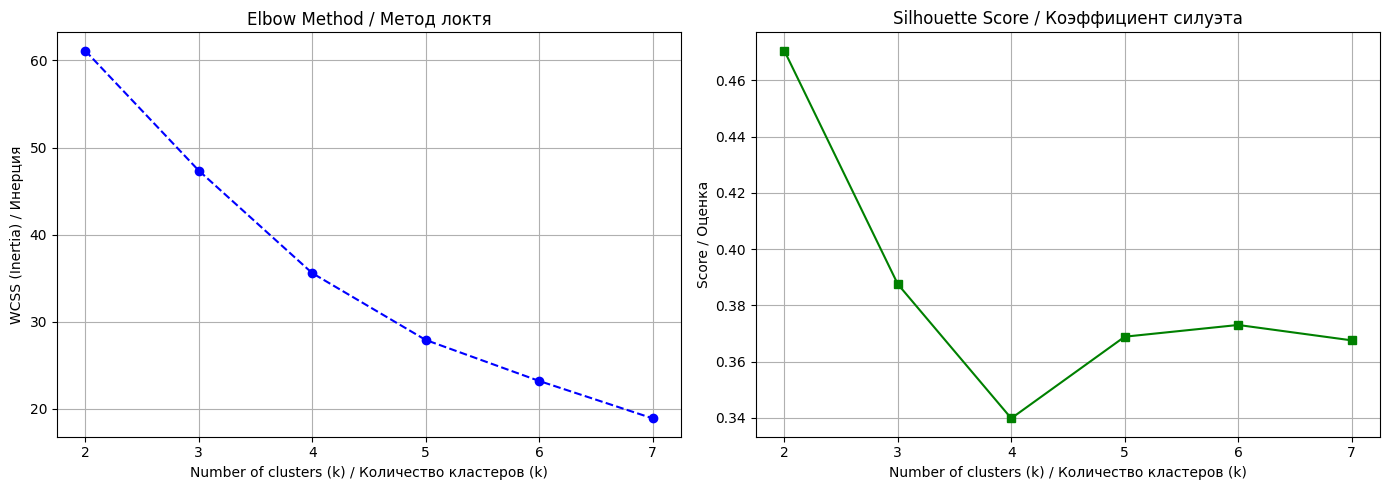

In [4]:
# Calculate WCSS (Inertia) and Silhouette Scores / Вычисление WCSS (инерции) и коэффициентов силуэта
wcss = []
sil_scores = []
K_range = range(2, 8)

for k in K_range:
    # random_state is set for reproducibility / random_state задан для воспроизводимости
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)
    wcss.append(kmeans.inertia_)
    sil_scores.append(silhouette_score(X_scaled, labels))

# Plot Elbow Method / График метода локтя
plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.plot(K_range, wcss, marker='o', linestyle='--', color='b')
plt.title('Elbow Method / Метод локтя')
plt.xlabel('Number of clusters (k) / Количество кластеров (k)')
plt.ylabel('WCSS (Inertia) / Инерция')
plt.grid(True)

# Plot Silhouette Score / График коэффициента силуэта
plt.subplot(1, 2, 2)
plt.plot(K_range, sil_scores, marker='s', linestyle='-', color='g')
plt.title('Silhouette Score / Коэффициент силуэта')
plt.xlabel('Number of clusters (k) / Количество кластеров (k)')
plt.ylabel('Score / Оценка')
plt.grid(True)

plt.tight_layout()
plt.show()

In [5]:
# Apply K-Means clustering with optimal K=3 / Применение кластеризации K-Means с оптимальным K=3
optimal_k = 3
kmeans_final = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
df_clean['Cluster'] = kmeans_final.fit_predict(X_scaled)

# Display mean values for interpretation / Отображение средних значений для интерпретации
cluster_summary = df_clean.groupby('Cluster')[features].mean().round(1)
cluster_summary.insert(0, 'Count / Количество', df_clean.groupby('Cluster').size())
print("Cluster Profiles / Профили кластеров:")
display(cluster_summary)

Cluster Profiles / Профили кластеров:


,Count / Количество,Work,Price,Salary
Cluster,,,,
0,11,1855.5,50.8,16.6
1,25,1789.2,85.0,59.0
2,10,2133.5,54.2,16.1


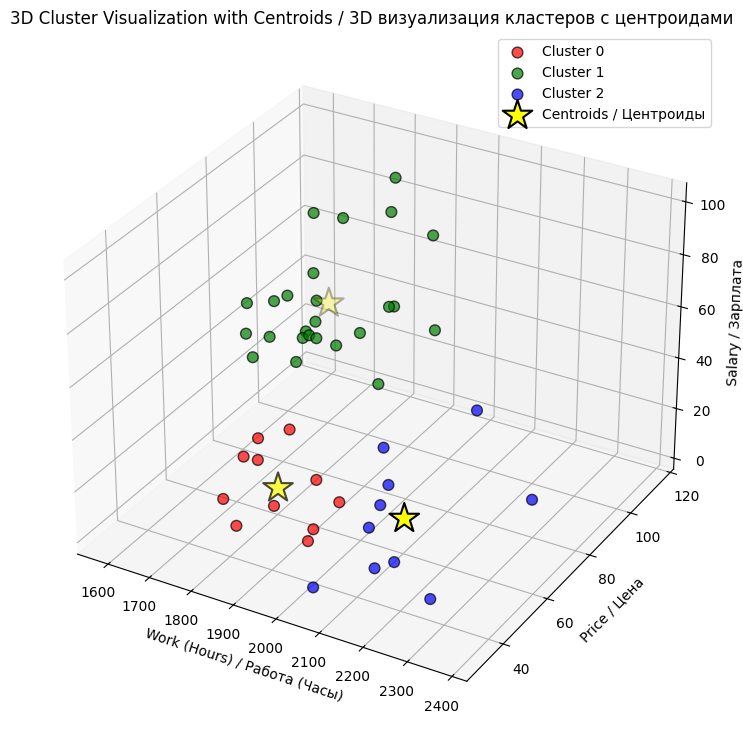

In [6]:
# 3D Visualization of clusters and centroids / 3D визуализация кластеров и центроидов
fig = plt.figure(figsize=(12, 9))
ax = fig.add_subplot(111, projection='3d')

# Map colors to clusters / Назначение цветов кластерам
colors = ['red', 'green', 'blue']
for cluster_id in range(optimal_k):
    cluster_data = df_clean[df_clean['Cluster'] == cluster_id]
    ax.scatter(cluster_data['Work'], cluster_data['Price'], cluster_data['Salary'],
               c=colors[cluster_id], label=f'Cluster {cluster_id}', s=60, edgecolors='k', alpha=0.7)

# Extract and INVERSE TRANSFORM the centroids / Извлечение и обратное преобразование центроидов
centroids_scaled = kmeans_final.cluster_centers_
centroids_original = scaler.inverse_transform(centroids_scaled)

# Plot the original-scaled centroids
# Построение центроидов в исходном масштабе
ax.scatter(centroids_original[:, 0], centroids_original[:, 1], centroids_original[:, 2],
           c='yellow', marker='*', s=500, edgecolor='black', linewidth=1.5,
           label='Centroids / Центроиды', zorder=10)

ax.set_xlabel('Work (Hours) / Работа (Часы)')
ax.set_ylabel('Price / Цена')
ax.set_zlabel('Salary / Зарплата')
ax.set_title('3D Cluster Visualization with Centroids / 3D визуализация кластеров с центроидами')
ax.legend()
plt.show()

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(


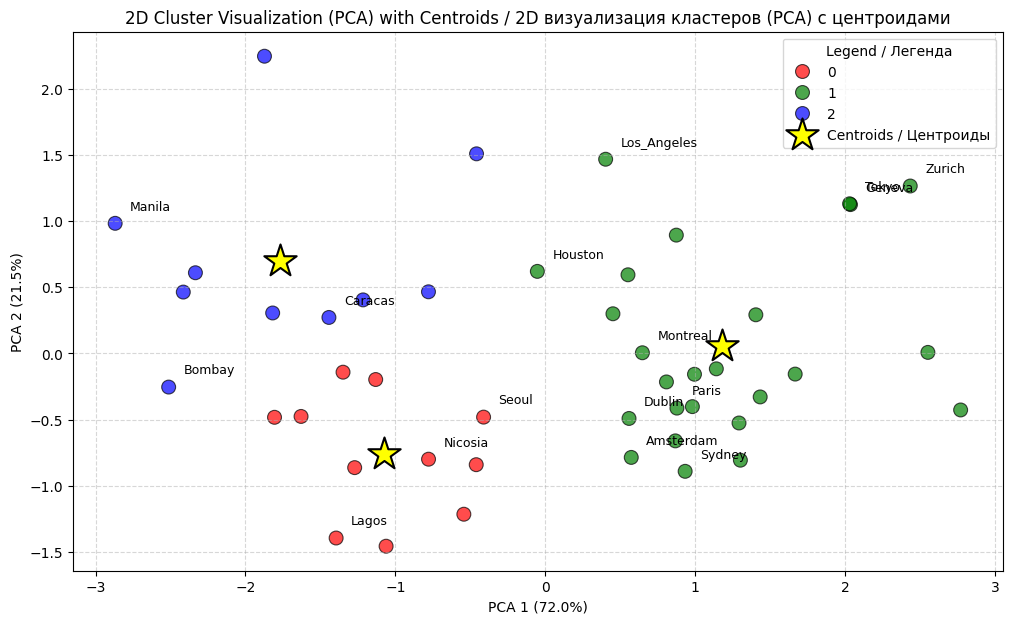

In [7]:
# Dimensionality reduction to 2D using PCA / Снижение размерности до 2D с помощью PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

df_clean['PCA1'] = X_pca[:, 0]
df_clean['PCA2'] = X_pca[:, 1]

# 2D Visualization / 2D визуализация
plt.figure(figsize=(12, 7))
sns.scatterplot(x='PCA1', y='PCA2', hue='Cluster', palette=['red', 'green', 'blue'],
                data=df_clean, s=100, edgecolor='k', alpha=0.7)

# Transform centroids into 2D PCA space / Преобразование центроидов в 2D пространство PCA
centroids_pca = pca.transform(kmeans_final.cluster_centers_)

# Plot the centroids / Построение центроидов
plt.scatter(centroids_pca[:, 0], centroids_pca[:, 1],
            c='yellow', marker='*', s=600, edgecolor='black', linewidth=1.5,
            label='Centroids / Центроиды', zorder=10)

# Add city names as annotations/ Добавление названий городов
for i, city in enumerate(df_clean.index):
    if i % 3 == 0:
        plt.text(df_clean['PCA1'].iloc[i] + 0.1, df_clean['PCA2'].iloc[i] + 0.1, city, fontsize=9)

plt.title('2D Cluster Visualization (PCA) with Centroids / 2D визуализация кластеров (PCA) с центроидами')
plt.xlabel(f'PCA 1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
plt.ylabel(f'PCA 2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
plt.grid(True, linestyle='--', alpha=0.5)

# Adjust legend / Настройка легенды
handles, labels = plt.gca().get_legend_handles_labels()
plt.legend(handles, labels, title='Legend / Легенда')
plt.show()

In [8]:
from scipy.stats import f_oneway

# Statistical Evaluation using ANOVA / Статистическая оценка с помощью ANOVA
print("=== ANOVA TEST (K-Means) / Тест ANOVA для K-Means ===\n")
for col in features:
    groups = [df_clean[df_clean['Cluster'] == i][col] for i in df_clean['Cluster'].unique()]
    f_stat, p_val = f_oneway(*groups)
    print(f"{col:<7}: F-value = {f_stat:.2f}, p-value = {p_val:.2e}")

print("\nConclusion: p-values < 0.05 indicate clusters are statistically distinct.")
print("Вывод: p-значения < 0.05 указывают на то, что кластеры статистически различимы.\n")
print("-" * 60 + "\n")

# Interpretation Table / Таблица интерпретации
kmeans_summary = df_clean.groupby('Cluster')[features].mean().round(0).astype(int)
kmeans_summary.insert(0, 'Размер (Size)', df_clean.groupby('Cluster').size())


cluster_names_km = {
    0: 'Moderate Work, Low Cost/ Средняя занятость, Низкие цены',
    1: 'High Income & Cost / Высокий доход и высокие цены',
    2: 'High Workload, Low Wage / Долгое рабочее время, Низкая зарплата'
}
kmeans_summary.insert(0, 'Название ', kmeans_summary.index.map(cluster_names_km))

print("=== Таблица Интерпретации K-Means (Tabel Interpretasi K-Means) ===\n")
display(kmeans_summary)

# 3. List of cities per cluster / Список городов по кластерам
for c in kmeans_summary.index:
    cities = df_clean[df_clean['Cluster'] == c].index.tolist()
    print(f"\nКластер {c}: {', '.join(cities)}")

=== ANOVA TEST (K-Means) / Тест ANOVA для K-Means ===

Work   : F-value = 35.87, p-value = 6.85e-10
Price  : F-value = 31.10, p-value = 4.43e-09
Salary : F-value = 65.88, p-value = 8.08e-14

Conclusion: p-values < 0.05 indicate clusters are statistically distinct.
Вывод: p-значения < 0.05 указывают на то, что кластеры статистически различимы.

------------------------------------------------------------

=== Таблица Интерпретации K-Means (Tabel Interpretasi K-Means) ===



,Название,Размер (Size),Work,Price,Salary
Cluster,,,,,
0,"Moderate Work, Low Cost/ Средняя занятость, Ни...",11,1855,51,17
1,High Income & Cost / Высокий доход и высокие цены,25,1789,85,59
2,"High Workload, Low Wage / Долгое рабочее время...",10,2134,54,16



Кластер 0: Athens, Buenos_Aires, Johannesburg, Lagos, Lisbon, Mexico_City, Nairobi, Nicosia, Rio_de_Janeiro, San_Paulo, Seoul

Кластер 1: Amsterdam, Brussels, Chicago, Copenhagen, Dublin, Dusseldorf, Frankfurt, Geneva, Helsinki, Houston, London, Los_Angeles, Luxembourg, Madrid, Milan, Montreal, New_York, Oslo, Paris, Stockholm, Sydney, Tokyo, Toronto, Vienna, Zurich

Кластер 2: Bogota, Bombay, Caracas, Hong_Kong, Kuala_Lumpur, Manila, Panama, Singpore, Taipei, Tel_Aviv


In [9]:
# Calculate the overall Silhouette Score for K=3 / Вычисление общего коэффициента силуэта для K=3
sil_score_kmeans = silhouette_score(X_scaled, df_clean['Cluster'])
print(f"=== Silhouette Evaluation (K-Means) / Оценка силуэта ===\n")
print(f"Overall Silhouette Score (K=3) / Общий коэффициент силуэта: {sil_score_kmeans:.3f}\n")

# Calculate Silhouette Score for each individual city / Вычисление коэффициента силуэта для каждого города (объекта)
sil_vals_kmeans = silhouette_samples(X_scaled, df_clean['Cluster'])

# Add the scores to the dataframe / Добавление оценок в датафрейм
df_clean['Sil_Score_KMeans'] = sil_vals_kmeans

# Display the first 10 rows to verify / Отображение первых 10 строк для проверки
print("Data with KMeans Clusters and Silhouette Scores / Данные с кластерами KMeans и оценками силуэта:")
display(df_clean[['Work', 'Price', 'Salary', 'Cluster', 'Sil_Score_KMeans']].head(10))

=== Silhouette Evaluation (K-Means) / Оценка силуэта ===

Overall Silhouette Score (K=3) / Общий коэффициент силуэта: 0.388

Data with KMeans Clusters and Silhouette Scores / Данные с кластерами KMeans и оценками силуэта:


,Work,Price,Salary,Cluster,Sil_Score_KMeans
City,,,,,
Amsterdam,1714,65.6,49.0,1,0.206534
Athens,1792,53.8,30.4,0,0.545334
Bogota,2152,37.9,11.5,2,0.347614
Bombay,2052,30.3,5.3,2,0.017604
Brussels,1708,73.8,50.5,1,0.408375
Buenos_Aires,1971,56.1,12.5,0,0.234383
Caracas,2041,61.0,10.9,2,0.080978
Chicago,1924,73.9,61.9,1,0.386722
Copenhagen,1717,91.3,62.9,1,0.578099
